# Spambase: Spam E-mail Classification

Machine Learning course project

## Step 1 – Understand the Problem

**Dataset.** The [UCI Spambase dataset](https://archive.ics.uci.edu/dataset/94/spambase) was created at Hewlett-Packard Labs in 1999. It contains **4,601 e-mails**, and each one is labelled as *spam* or *not spam*. The spam e-mails came from the company's postmaster and from people who had reported spam. The non-spam e-mails came from work and personal mail. The raw text is not included: each e-mail has already been converted into **57 numeric features**.

**Features (57 numeric columns):**

| Group | Count | Meaning |
|---|---|---|
| `word_freq_WORD` | 48 | Percentage of words in the e-mail that match `WORD` (e.g. `free`, `money`, `remove`, `george`). Calculated as 100 × (times WORD appears) / (total words). |
| `char_freq_CHAR` | 6 | Percentage of characters in the e-mail that are `CHAR` (`;` `(` `[` `!` `$` `#`). |
| `capital_run_length_average` | 1 | Average length of uninterrupted runs of CAPITAL letters. |
| `capital_run_length_longest` | 1 | Length of the longest run of capital letters. |
| `capital_run_length_total` | 1 | Total number of capital letters in the e-mail. |

**Target variable.** `spam`: **1 = spam**, **0 = not spam** (a legitimate e-mail, sometimes called "ham").

**Prediction goal.** This is a **binary classification** problem. Given the 57 features of an e-mail, we want to predict whether it is spam (1) or not (0). A good spam filter should catch as much spam as possible. It must also rarely mark a real e-mail as spam (a *false positive*), because losing a legitimate e-mail is usually worse than letting one spam message through.

> Note: some words, such as `george` and `hp`, and the number `650` (an area code) are specific to the HP Labs mailboxes. They are good for telling HP's personal mail apart from spam, but they would not work as well for a general spam filter.

## Step 2 – Explore the Data

### 2.1 Import the libraries

In [1]:
# pandas = tables of data (like a spreadsheet you control with code)
import pandas as pd
# matplotlib = the basic plotting library in Python
import matplotlib.pyplot as plt
# seaborn = built on top of matplotlib, makes nicer statistical charts with less code
import seaborn as sns

# Use a clean seaborn style for every chart in this notebook
sns.set_theme(style="whitegrid")
# Show all columns when we print a wide table (we have 58 columns)
pd.set_option("display.max_columns", 60)

### 2.2 Load the data with proper column names

`spambase.data` has **no header row**, so we create the 58 column names ourselves. The names come from the UCI documentation file `spambase.names`.

> **To run this notebook:** keep the file `spambase.data` (submitted with this notebook) in the same folder as the notebook.

In [2]:
# The 48 words used in the word_freq_* features, in the exact order from the UCI documentation
words = [
    "make", "address", "all", "3d", "our", "over", "remove", "internet",
    "order", "mail", "receive", "will", "people", "report", "addresses", "free",
    "business", "email", "you", "credit", "your", "font", "000", "money",
    "hp", "hpl", "george", "650", "lab", "labs", "telnet", "857",
    "data", "415", "85", "technology", "1999", "parts", "pm", "direct",
    "cs", "meeting", "original", "project", "re", "edu", "table", "conference",
]

# The 6 characters used in the char_freq_* features
chars = [";", "(", "[", "!", "$", "#"]

# Build the full list of column names.
# A "list comprehension" like [... for w in words] is a short for-loop that builds a list.
column_names = (
    ["word_freq_" + w for w in words]          # 48 word features
    + ["char_freq_" + c for c in chars]        # 6 character features
    + ["capital_run_length_average",           # 3 capital-letter features
       "capital_run_length_longest",
       "capital_run_length_total"]
    + ["spam"]                                 # the target column (1 = spam, 0 = not spam)
)

# Read the file. header=None tells pandas the file has no header row;
# names=... gives the columns our own names.
df = pd.read_csv("spambase.data", header=None, names=column_names)

# Quick sanity check: we expect 57 features + 1 target = 58 names
print("Number of column names:", len(column_names))

Number of column names: 58


### 2.3 Size of the dataset and missing values

In [3]:
# df.shape gives a tuple (number_of_rows, number_of_columns)
rows, cols = df.shape
print("Rows (e-mails):", rows)
print("Columns:", cols, "(57 features + 1 target)")

# isnull() marks every missing cell as True; .sum() counts them per column;
# the second .sum() adds up all columns into one total.
total_missing = df.isnull().sum().sum()
print("Total missing values in the whole table:", total_missing)

Rows (e-mails): 4601
Columns: 58 (57 features + 1 target)
Total missing values in the whole table: 0


In [4]:
# Also check for duplicate rows (identical e-mails), useful to know for later modelling
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 391


There are **no missing values**, so we do not need to fill in or remove anything. Some rows are exact duplicates. We note this here and will decide how to handle them in the modelling part.

### 2.4 Class counts (spam vs. not spam)

In [5]:
# value_counts() counts how many times each value appears in the 'spam' column
counts = df["spam"].value_counts()
# normalize=True gives proportions instead of counts; * 100 turns them into percentages
percentages = df["spam"].value_counts(normalize=True) * 100

# Put both into one small table so they are easy to read side by side
class_table = pd.DataFrame({
    "count": counts,
    "percent (%)": percentages.round(2),
})
# Give the index readable labels instead of 0 / 1
class_table.index = class_table.index.map({0: "0 = not spam", 1: "1 = spam"})
class_table

,count,percent (%)
spam,,
0 = not spam,2788,60.6
1 = spam,1813,39.4


### 2.5 First rows and summary statistics

In [6]:
# head() shows the first 5 rows, a quick look at what the data looks like
df.head()

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,word_freq_receive,word_freq_will,word_freq_people,word_freq_report,word_freq_addresses,word_freq_free,word_freq_business,word_freq_email,word_freq_you,word_freq_credit,word_freq_your,word_freq_font,word_freq_000,word_freq_money,word_freq_hp,word_freq_hpl,word_freq_george,word_freq_650,word_freq_lab,word_freq_labs,word_freq_telnet,word_freq_857,word_freq_data,word_freq_415,word_freq_85,word_freq_technology,word_freq_1999,word_freq_parts,word_freq_pm,word_freq_direct,word_freq_cs,word_freq_meeting,word_freq_original,word_freq_project,word_freq_re,word_freq_edu,word_freq_table,word_freq_conference,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,spam
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,0.00,0.64,0.00,0.00,0.00,0.32,0.00,1.29,1.93,0.00,0.96,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00,0.0,0.0,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,0.21,0.79,0.65,0.21,0.14,0.14,0.07,0.28,3.47,0.00,1.59,0.0,0.43,0.43,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.07,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00,0.0,0.0,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,0.38,0.45,0.12,0.00,1.75,0.06,0.06,1.03,1.36,0.32,0.51,0.0,1.16,0.06,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.06,0.0,0.0,0.12,0.0,0.06,0.06,0.0,0.0,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,0.31,0.31,0.31,0.00,0.00,0.31,0.00,0.00,3.18,0.00,0.31,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00,0.0,0.0,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,0.31,0.31,0.31,0.00,0.00,0.31,0.00,0.00,3.18,0.00,0.31,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00,0.0,0.0,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


In [7]:
# describe() gives count, mean, standard deviation, min, quartiles and max for every column.
# .T (transpose) flips the table so each feature is a row. This is easier to read with 58 columns.
df.describe().T

,count,mean,std,min,25%,50%,75%,max
word_freq_make,4601.0,0.104553,0.305358,0.0,0.000,0.000,0.000,4.540
word_freq_address,4601.0,0.213015,1.290575,0.0,0.000,0.000,0.000,14.280
word_freq_all,4601.0,0.280656,0.504143,0.0,0.000,0.000,0.420,5.100
word_freq_3d,4601.0,0.065425,1.395151,0.0,0.000,0.000,0.000,42.810
word_freq_our,4601.0,0.312223,0.672513,0.0,0.000,0.000,0.380,10.000
word_freq_over,4601.0,0.095901,0.273824,0.0,0.000,0.000,0.000,5.880
word_freq_remove,4601.0,0.114208,0.391441,0.0,0.000,0.000,0.000,7.270
word_freq_internet,4601.0,0.105295,0.401071,0.0,0.000,0.000,0.000,11.110
word_freq_order,4601.0,0.090067,0.278616,0.0,0.000,0.000,0.000,5.260
word_freq_mail,4601.0,0.239413,0.644755,0.0,0.000,0.000,0.160,18.180


**Observations:** Most `word_freq_*` and `char_freq_*` features have a median (50%) of **0**. Each word appears in only a small share of e-mails, so these columns are mostly zeros with a few large values. The three `capital_run_length_*` features use a much larger scale (for example, `capital_run_length_total` goes up to about 15,800). We will probably need to **scale** the features before training some models.

### 2.6 Visualisations

#### Chart 1 – Class distribution

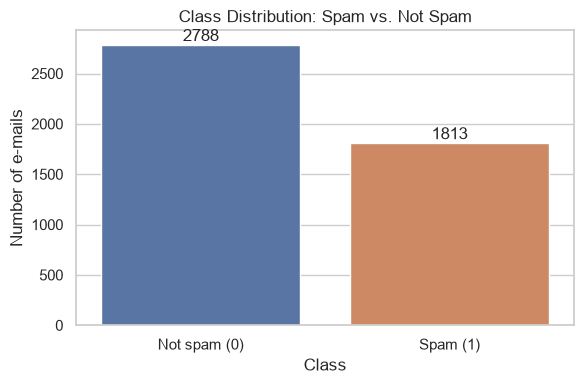

In [8]:
# Create a figure (the whole picture) and an axes (the plot area inside it)
fig, ax = plt.subplots(figsize=(6, 4))

# countplot counts the rows for each value of 'spam' and draws one bar per class
sns.countplot(data=df, x="spam", hue="spam", palette=["#4C72B0", "#DD8452"], legend=False, ax=ax)

# Replace the 0 / 1 tick labels with readable names
ax.set_xticks([0, 1])
ax.set_xticklabels(["Not spam (0)", "Spam (1)"])

# Write the count on top of each bar
for container in ax.containers:
    ax.bar_label(container)

# Title and axis labels
ax.set_title("Class Distribution: Spam vs. Not Spam")
ax.set_xlabel("Class")
ax.set_ylabel("Number of e-mails")

plt.tight_layout()  # stop labels from being cut off
plt.show()

The dataset has **2,788 non-spam (≈60.6%)** and **1,813 spam (≈39.4%)** e-mails. The classes are only mildly imbalanced, so accuracy is a reasonable metric. Precision and recall will still be worth checking.

#### Chart 2 – Average frequency of key spam words/characters by class

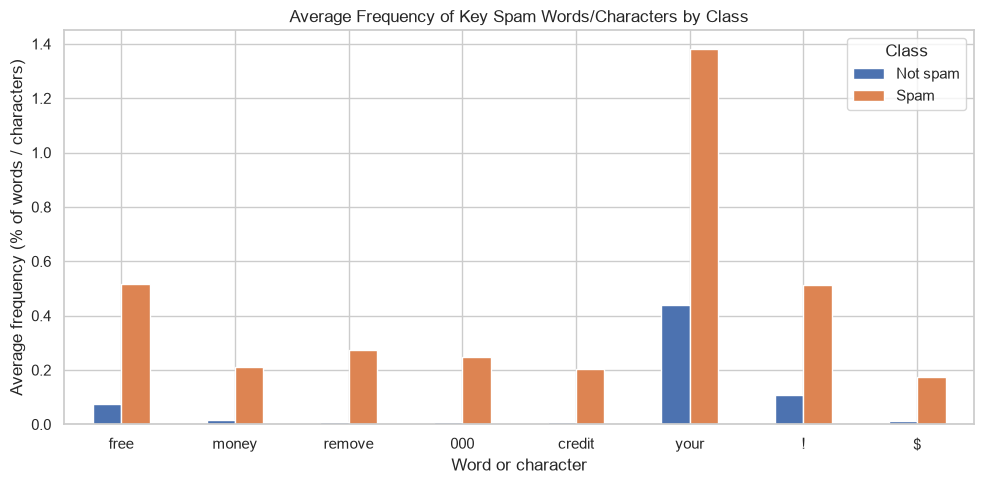

,free,money,remove,000,credit,your,!,$
Not spam,0.074,0.017,0.009,0.007,0.008,0.439,0.110,0.012
Spam,0.518,0.213,0.275,0.247,0.206,1.380,0.514,0.174


In [9]:
# A hand-picked set of features that often appear in spam
key_features = [
    "word_freq_free", "word_freq_money", "word_freq_remove", "word_freq_000",
    "word_freq_credit", "word_freq_your", "char_freq_!", "char_freq_$",
]

# groupby("spam") splits the rows into two groups (0 and 1);
# .mean() computes the average of each key feature inside each group.
avg_by_class = df.groupby("spam")[key_features].mean()

# Rename the index and columns so the chart legend and x-axis are easy to read
avg_by_class.index = ["Not spam", "Spam"]
avg_by_class.columns = [c.replace("word_freq_", "").replace("char_freq_", "") for c in key_features]

# .T flips the table so each feature becomes a group of two bars (Not spam / Spam)
ax = avg_by_class.T.plot(kind="bar", figsize=(10, 5), color=["#4C72B0", "#DD8452"])

ax.set_title("Average Frequency of Key Spam Words/Characters by Class")
ax.set_xlabel("Word or character")
ax.set_ylabel("Average frequency (% of words / characters)")
ax.legend(title="Class")
plt.xticks(rotation=0)  # keep the x labels horizontal
plt.tight_layout()
plt.show()

# Also print the numbers behind the chart
avg_by_class.round(3)

Every one of these words and characters appears **much more often in spam** than in normal e-mail. `your`, `free`, `!`, `remove` and `000` show the biggest differences. These features should help a model tell the two classes apart.

#### Chart 3 – Boxplot of `char_freq_!` by class

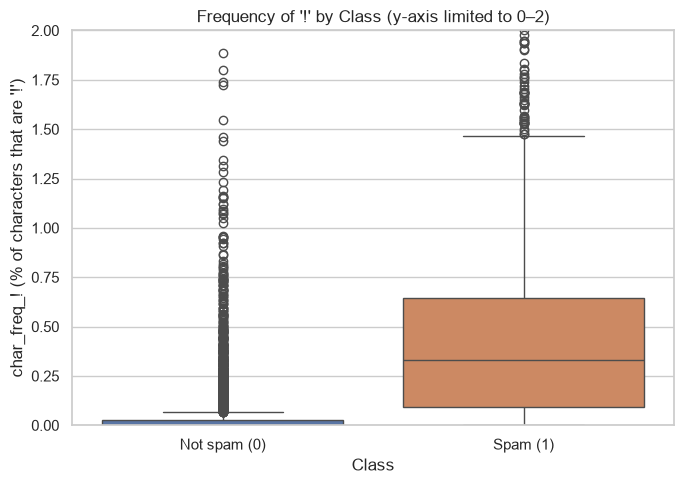

spam
0    0.000
1    0.331
Name: char_freq_!, dtype: float64


In [10]:
fig, ax = plt.subplots(figsize=(7, 5))

# A boxplot shows the median (middle line), the middle 50% of values (the box)
# and outliers (dots). We draw one box per class.
sns.boxplot(data=df, x="spam", y="char_freq_!", hue="spam",
            palette=["#4C72B0", "#DD8452"], legend=False, ax=ax)

# A few e-mails have extreme values (up to ~33), which squash the boxes.
# We limit the y-axis to 0-2 so the boxes are visible (the outliers above 2 are just cut off from view).
ax.set_ylim(0, 2)

ax.set_xticks([0, 1])
ax.set_xticklabels(["Not spam (0)", "Spam (1)"])
ax.set_title("Frequency of '!' by Class (y-axis limited to 0–2)")
ax.set_xlabel("Class")
ax.set_ylabel("char_freq_! (% of characters that are '!')")
plt.tight_layout()
plt.show()

# Print the median for each class to back up what the chart shows
print(df.groupby("spam")["char_freq_!"].median())

For non-spam e-mails the median frequency of `!` is **0**, so most normal e-mails contain no exclamation marks at all. For spam the median is clearly above zero and the box is much taller. This makes `char_freq_!` one of the strongest single signals for spam.

#### Chart 4 – Top 10 features most correlated with the target

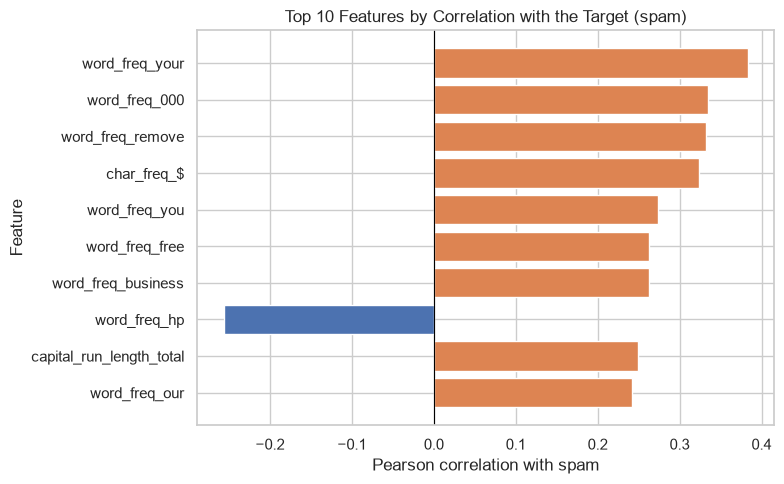

word_freq_your              0.383
word_freq_000               0.335
word_freq_remove            0.332
char_freq_$                 0.324
word_freq_you               0.274
word_freq_free              0.263
word_freq_business          0.263
word_freq_hp               -0.257
capital_run_length_total    0.249
word_freq_our               0.242
Name: spam, dtype: float64

In [11]:
# df.corr() computes the correlation between every pair of columns (values from -1 to +1).
# We only need each feature's correlation with 'spam', so we pick that column and drop 'spam' itself.
corr_with_target = df.corr()["spam"].drop("spam")

# Sort by the absolute value (strength), ignoring the sign, and keep the 10 strongest
top10 = corr_with_target.reindex(corr_with_target.abs().sort_values(ascending=False).index).head(10)

# Colour positive correlations orange (linked to spam) and negative ones blue (linked to not spam)
colors = ["#DD8452" if v > 0 else "#4C72B0" for v in top10.values]

fig, ax = plt.subplots(figsize=(8, 5))
# Horizontal bar chart: feature names on the y-axis, correlation on the x-axis
ax.barh(top10.index, top10.values, color=colors)
ax.invert_yaxis()  # put the strongest feature at the top
ax.axvline(0, color="black", linewidth=0.8)  # vertical line at zero

ax.set_title("Top 10 Features by Correlation with the Target (spam)")
ax.set_xlabel("Pearson correlation with spam")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

top10.round(3)

The features most strongly linked to spam are `your`, `000`, `remove`, `$`, `you`, `free` and `business`. They have positive correlations, so a higher frequency means more likely spam. `capital_run_length_total` is also positive: spam tends to use many CAPITAL letters. `hp` is the only feature in the top 10 with a negative correlation. It points towards **not** spam, because it comes from the HP Labs mailboxes. All the correlations are moderate (below 0.4), so no single feature is enough. A model will need to combine several features.

### Summary of the data exploration

- 4,601 e-mails, 57 numeric features, binary target `spam`. There are **no missing values**, but there are some duplicate rows.
- The class balance is about **61% not spam / 39% spam**.
- Most features are **sparse** (mostly zeros) and use **very different scales**. The capital-letter features are much larger, so scaling will matter for some models.
- Words such as *free*, *money*, *your*, *000* and *remove*, and the characters `!` and `$`, are clear spam indicators. *hp*, *hpl* and *george* are indicators of non-spam.

*Next: Step 3 prepares the data for modelling.*

## Step 3 – Prepare the Data

Before training any model, we make sure the data is clean and in the right format:

1. Handle missing values
2. Encode text categories (if any)
3. Remove duplicate rows
4. Separate the features (X) from the target (y)
5. Split into training and test sets (80/20, stratified, `random_state=42`)
6. Scale the features, fitting the scaler on the training set only to avoid data leakage

### 3.1 Handle missing values

Most models in scikit-learn cannot handle empty cells, so we first check every column for missing values (`NaN`).

In [12]:
# isnull() gives True for each empty cell; sum() counts them for each column
missing_per_column = df.isnull().sum()

# Show only the columns that have at least one missing value (should be an empty list)
print("Columns with missing values:", list(missing_per_column[missing_per_column > 0].index))

# Total number of missing cells in the whole table
print("Total missing values:", missing_per_column.sum())

Columns with missing values: []
Total missing values: 0


There are **no missing values** in any of the 58 columns. We do not need to remove rows or fill in values (imputation), so no changes are made in this step.

### 3.2 Encode text categories (if any)

Models work with numbers only. If a column contained text, for example "yes" / "no", we would have to convert it into numbers, for instance with one-hot encoding. We check the data type of every column.

In [13]:
# dtypes shows the data type of each column; value_counts() counts how many columns have each type
print("Column data types:")
print(df.dtypes.value_counts())

# select_dtypes(include="object") picks the text (string) columns, if there are any
text_columns = df.select_dtypes(include="object").columns
print("\nText (categorical) columns:", list(text_columns))

Column data types:
float64    55
int64       3
Name: count, dtype: int64

Text (categorical) columns: []


All 58 columns are **numeric**: the features are `float64` or `int64`, and the target `spam` is already 0 / 1. There are **no text categories**, so **no encoding is needed**.

### 3.3 Remove duplicate rows

In Step 2 we found **391 duplicate rows**: e-mails whose 57 feature values *and* label are exactly the same as another row. We remove them for two reasons:

1. **Avoid data leakage.** We will soon split the data into a training set and a test set. If a duplicate ended up in both, the model would be tested on an e-mail it already saw during training. Its test score would then look better than it really is.
2. **Avoid giving some e-mails extra weight.** Each copy counts again during training, so a repeated e-mail would matter more than the others for no good reason.

We keep the **first** copy of each duplicated e-mail and drop the rest.

In [14]:
# duplicated() returns True for every row that is an exact copy of an earlier row
duplicate_mask = df.duplicated()
print("Duplicate rows found:", duplicate_mask.sum())

# Which class do the duplicates belong to? (0 = not spam, 1 = spam)
print("\nDuplicates per class:")
print(df[duplicate_mask]["spam"].value_counts())

Duplicate rows found: 391

Duplicates per class:
spam
0    257
1    134
Name: count, dtype: int64


In [15]:
# Remember the size before cleaning so we can compare
rows_before = len(df)

# drop_duplicates() removes the copies and keeps the first occurrence of each row.
# reset_index(drop=True) renumbers the rows 0, 1, 2, ... so there are no gaps in the index.
df = df.drop_duplicates().reset_index(drop=True)

print("Rows before:", rows_before)
print("Rows after: ", len(df))
print("Rows removed:", rows_before - len(df))

Rows before: 4601
Rows after:  4210
Rows removed: 391


In [16]:
# Check the class balance again after removing duplicates
new_class_table = pd.DataFrame({
    "count": df["spam"].value_counts(),
    "percent (%)": (df["spam"].value_counts(normalize=True) * 100).round(2),
})
new_class_table.index = new_class_table.index.map({0: "0 = not spam", 1: "1 = spam"})
new_class_table

,count,percent (%)
spam,,
0 = not spam,2531,60.12
1 = spam,1679,39.88


In [17]:
# Extra check: are there e-mails with identical features but DIFFERENT labels?
# We look for duplicates using only the 57 feature columns (everything except 'spam').
feature_columns = df.columns.drop("spam")
conflicting = df[df.duplicated(subset=feature_columns, keep=False)]
print("Rows with identical features but different labels:", len(conflicting))
conflicting[["capital_run_length_average", "capital_run_length_longest", "capital_run_length_total", "spam"]]

Rows with identical features but different labels: 6


,capital_run_length_average,capital_run_length_longest,capital_run_length_total,spam
62,1.411,15,96,1
135,2.562,35,123,1
436,1.864,32,910,1
1848,2.562,35,123,0
2901,1.411,15,96,0
2971,1.864,32,910,0


**Result:** 391 duplicate rows were removed (257 not spam, 134 spam), which leaves **4,210 unique e-mails**. The class balance hardly changed: about **60.1% not spam / 39.9% spam**, compared with 60.6% / 39.4% before. Removing the duplicates did not make the data unbalanced.

There are also **3 pairs** of e-mails that have exactly the same features but opposite labels. We cannot tell which label is correct, and 6 rows out of 4,210 is too few to affect the results, so we keep them as they are.

### 3.4 Separate the features (X) and the target (y)

Machine-learning models need the inputs and the answer as two separate objects:

- **`X`**: the 57 feature columns. This is the information the model *sees* about each e-mail.
- **`y`**: the `spam` column. This is the answer the model has to *learn to predict* (1 = spam, 0 = not spam).

By convention, `X` is written with a capital letter because it is a table (2-D), and `y` with a small letter because it is a single column (1-D).

In [18]:
# X = every column except 'spam' (drop() returns a copy, so df itself is not changed)
X = df.drop(columns="spam")

# y = only the 'spam' column
y = df["spam"]

# shape shows (rows, columns); y has no second number because it is a single column
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (4210, 57)
y shape: (4210,)


### 3.5 Split the data into a training set and a test set

We need to know how well the model works on e-mails it has **never seen**. So we hide part of the data from it during training:

- **Training set (80%)**: used to train the model.
- **Test set (20%)**: kept aside and used only once, at the end, to measure the final performance.

Two important settings:

- `stratify=y` keeps the same spam / not-spam ratio (about 60% / 40%) in both sets. Without it, one set could get more spam than the other just by chance.
- `random_state=42` fixes the random shuffle, so we get exactly the same split every time we run the notebook. This makes our results reproducible.

In [19]:
# train_test_split comes from scikit-learn, the standard machine-learning library for Python
from sklearn.model_selection import train_test_split

# It shuffles the rows and returns four pieces:
#   X_train, y_train -> features and answers used for training
#   X_test,  y_test  -> features and answers kept aside for the final test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,      # 20% of the rows go to the test set
    stratify=y,         # keep the same class ratio in both sets
    random_state=42,    # fixed seed -> same split every run
)

print("Training set:", X_train.shape[0], "e-mails")
print("Test set:    ", X_test.shape[0], "e-mails")

Training set: 3368 e-mails
Test set:     842 e-mails


In [20]:
# Check that stratify worked: the spam percentage should be (almost) the same in both sets
split_check = pd.DataFrame({
    "train (%)": (y_train.value_counts(normalize=True) * 100).round(2),
    "test (%)": (y_test.value_counts(normalize=True) * 100).round(2),
})
split_check.index = split_check.index.map({0: "0 = not spam", 1: "1 = spam"})
split_check

,train (%),test (%)
spam,,
0 = not spam,60.12,60.1
1 = spam,39.88,39.9


Both sets have practically the same class ratio as the full dataset, about **60% not spam / 40% spam**. This means the test set is a fair sample of the data.

### 3.6 Feature scaling (standardisation)

In Step 2 we saw that the features use very different scales. Most `word_freq_*` values are between 0 and a few units, while `capital_run_length_total` goes up to about 15,800. Some models, such as Logistic Regression, KNN and SVM, compare raw numbers or distances. For those models, large-scale features would dominate just because their numbers are bigger.

`StandardScaler` rescales every feature to **mean = 0** and **standard deviation = 1**, using the formula:

$$z = \frac{x - \text{mean}}{\text{standard deviation}}$$

**Important rule:** the scaler learns the mean and standard deviation from the **training set only** (`fit_transform`). It then applies those same numbers to the test set (`transform`). If we also learned from the test set, information from the "unseen" data would leak into training, and the test score would no longer be honest.

We keep the **unscaled** `X_train` / `X_test` as well. Tree-based models, such as Decision Tree and Random Forest, do not need scaling.

In [21]:
from sklearn.preprocessing import StandardScaler

# Create the scaler object (it has not learned anything yet)
scaler = StandardScaler()

# fit_transform on TRAIN: learn each column's mean and std, then scale the training data
X_train_scaled = scaler.fit_transform(X_train)

# transform on TEST: reuse the mean and std learned from TRAIN (no new learning here!)
X_test_scaled = scaler.transform(X_test)

# The scaler returns plain NumPy arrays; turn them back into DataFrames so we keep the column names
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X.columns, index=X_test.index)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape: ", X_test_scaled.shape)

X_train_scaled shape: (3368, 57)
X_test_scaled shape:  (842, 57)


In [22]:
# Compare a few features before and after scaling (training set)
example_cols = ["word_freq_free", "char_freq_!", "capital_run_length_total"]

before = X_train[example_cols].agg(["mean", "std"]).T   # mean and std of the original values
after = X_train_scaled[example_cols].agg(["mean", "std"]).T  # mean and std after scaling

comparison = pd.concat({"before scaling": before, "after scaling": after}, axis=1)
comparison.round(3)

before scaling          after scaling     
                                   mean      std          mean  std
word_freq_free                    0.257    0.788           0.0  1.0
char_freq_!                       0.286    0.857          -0.0  1.0
capital_run_length_total        288.178  631.485           0.0  1.0

Before scaling, the features had very different means and spreads. `capital_run_length_total` has a mean in the hundreds, while `word_freq_free` is below 1. After scaling, every feature in the training set has a mean of **0** and a standard deviation of **1**, so they all contribute on the same scale.

**The data is now ready for modelling:**

| Variable | Contents | Use with |
|---|---|---|
| `X_train`, `X_test` | original (unscaled) features | tree-based models (Decision Tree, Random Forest) |
| `X_train_scaled`, `X_test_scaled` | standardised features | scale-sensitive models (Logistic Regression, KNN, SVM) |
| `y_train`, `y_test` | target labels (0 / 1) | all models |

## Step 4 – Train the Models

We train three classification models:

| Model | Data used | Why |
|---|---|---|
| Logistic Regression | **scaled** features | Linear model that is sensitive to feature scale |
| Decision Tree | original features | Splits on one feature at a time, so scale does not matter |
| Random Forest | original features | Many decision trees combined, so scale does not matter either |

All models are trained on the **training set only**. The test set stays hidden until Step 5.

To check that a model is stable, we also use **5-fold cross-validation** on the training set. The training data is split into 5 parts. The model is trained 5 times, each time on 4 parts and checked on the 5th part, and we look at the average score. This uses only training data, so the test set stays untouched.

In [23]:
# Model classes from scikit-learn
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
# Tools for cross-validation and hyper-parameter search
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV

# The same 5-fold split is reused for every model so the comparison is fair.
# "Stratified" keeps the spam ratio the same in every fold; shuffle + random_state make it reproducible.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

### 4.1 Logistic Regression

Logistic Regression gives each feature a **weight**. It multiplies every feature by its weight, adds the results up, and turns that sum into a probability between 0 and 1 using the *sigmoid* function. If the probability is ≥ 0.5, the e-mail is predicted as spam. During training the model learns the weights that best separate spam from non-spam.

In [24]:
# Create the model. max_iter=1000 gives the solver enough steps to finish learning.
log_reg = LogisticRegression(max_iter=1000, random_state=42)

# fit() = train the model on the SCALED training data
log_reg.fit(X_train_scaled, y_train)

# 5-fold cross-validated F1-score on the training set (a stability check, not the final result)
lr_cv_f1 = cross_val_score(log_reg, X_train_scaled, y_train, cv=cv, scoring="f1")
print("Cross-validation F1 per fold:", lr_cv_f1.round(3))
print("Mean CV F1: %.3f (+/- %.3f)" % (lr_cv_f1.mean(), lr_cv_f1.std()))

Cross-validation F1 per fold: [0.884 0.906 0.887 0.896 0.915]
Mean CV F1: 0.897 (+/- 0.011)


In [25]:
# Show which features the model thinks matter most (the largest weights).
# Positive weight -> pushes towards spam, negative weight -> pushes towards not spam.
coefficients = pd.Series(log_reg.coef_[0], index=X.columns)

top_positive = coefficients.sort_values(ascending=False).head(5)   # strongest spam signals
top_negative = coefficients.sort_values().head(5)                  # strongest non-spam signals

print("Top 5 words/characters pushing towards SPAM:")
print(top_positive.round(2))
print("\nTop 5 words/characters pushing towards NOT SPAM:")
print(top_negative.round(2))

Top 5 words/characters pushing towards SPAM:
char_freq_$                   1.23
word_freq_remove              1.05
capital_run_length_longest    1.05
word_freq_3d                  0.98
char_freq_#                   0.87
dtype: float64

Top 5 words/characters pushing towards NOT SPAM:
word_freq_george    -4.02
word_freq_hp        -2.48
word_freq_edu       -1.34
word_freq_meeting   -1.22
word_freq_cs        -1.19
dtype: float64


The model reaches a mean cross-validation F1 of about **0.90**, with little variation between folds, so it is stable. Its weights are easy to interpret. `$`, `remove`, long runs of capital letters, `3d` and `#` push towards spam. Words linked to the HP Labs mailboxes and university work (`george`, `hp`, `edu`, `meeting`, `cs`) push strongly towards not spam.

### 4.2 Decision Tree

A Decision Tree asks a series of yes/no questions, for example *"Is `char_freq_$` > 0.05?"*. Each answer leads to another question until a final decision (spam / not spam) is reached. It works like a long chain of `if / else` statements, but the computer chooses the questions automatically.

**Problem: overfitting.** If we let a tree grow without limits, it keeps adding questions until it memorises every training e-mail. It then does very well on the training data but generalises worse to new e-mails. We first train an unlimited tree to see this. Then we use `GridSearchCV` to choose a better **maximum depth** and **minimum samples per leaf**, using cross-validation on the training set only.

In [26]:
# 1) A tree with no limits (default settings)
full_tree = DecisionTreeClassifier(random_state=42)
full_tree.fit(X_train, y_train)

# get_depth() = how many questions deep the tree became
print("Unlimited tree depth:", full_tree.get_depth())
# score() returns accuracy; on the training data it is almost 100% -> a sign of memorising
print("Unlimited tree TRAINING accuracy: %.3f" % full_tree.score(X_train, y_train))

Unlimited tree depth: 31
Unlimited tree TRAINING accuracy: 0.999


In [27]:
# 2) Try different tree sizes and keep the one with the best cross-validated F1-score.
# param_grid lists the values to try: 6 depths x 4 leaf sizes = 24 combinations, each tested with 5-fold CV.
param_grid = {
    "max_depth": [3, 5, 7, 10, 15, None],      # None = no depth limit
    "min_samples_leaf": [1, 5, 10, 20],       # minimum e-mails allowed in a final leaf
}

grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),  # the model to tune
    param_grid,                               # the settings to try
    cv=cv,                                    # 5-fold cross-validation (training set only)
    scoring="f1",                             # choose the settings with the best F1-score
)
grid_search.fit(X_train, y_train)

print("Best settings found:", grid_search.best_params_)
print("Best mean CV F1: %.3f" % grid_search.best_score_)

# best_estimator_ is the tree retrained on the whole training set with the best settings
decision_tree = grid_search.best_estimator_
print("Tuned tree TRAINING accuracy: %.3f" % decision_tree.score(X_train, y_train))

# Cross-validated F1 of the tuned tree (for the comparison table later)
dt_cv_f1 = cross_val_score(decision_tree, X_train, y_train, cv=cv, scoring="f1")

Best settings found: {'max_depth': 10, 'min_samples_leaf': 1}
Best mean CV F1: 0.888
Tuned tree TRAINING accuracy: 0.966


The unlimited tree grew **31 levels deep** and scored **99.9%** on the training data. It memorised the training e-mails. Cross-validation chose **`max_depth=10`**, which gives a smaller, simpler tree. Its training accuracy (≈96.6%) is closer to what we can expect on new data, so it overfits less.

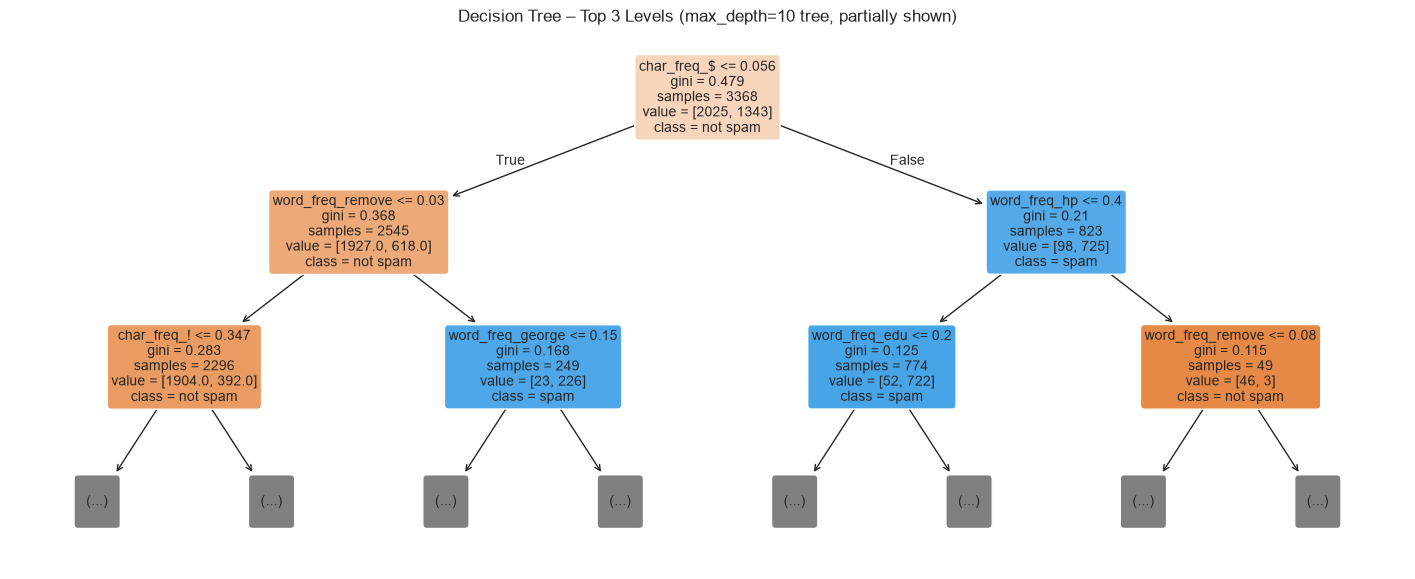

In [28]:
from sklearn.tree import plot_tree

# Draw only the top 3 levels of the tuned tree so it stays readable
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(
    decision_tree,
    max_depth=2,                              # show levels 0, 1 and 2 only
    feature_names=list(X.columns),            # use the real feature names
    class_names=["not spam", "spam"],         # label the classes
    filled=True,                              # colour boxes by the majority class
    rounded=True,
    fontsize=10,
    ax=ax,
)
ax.set_title("Decision Tree – Top 3 Levels (max_depth=10 tree, partially shown)")
plt.show()

The first question the tree asks is about `char_freq_$`, and the next ones use `word_freq_remove`, `word_freq_hp` and `char_freq_!`. These are the same strong signals we found in Step 2. Orange boxes are mostly *not spam* and blue boxes are mostly *spam*. A darker colour means the group is "purer", with fewer e-mails from the other class mixed in.

### 4.3 Random Forest

A Random Forest trains **many decision trees** (here 300), and each tree sees slightly different data:
- each tree is trained on a random sample of the training e-mails (*bootstrap sampling*), and
- at each question, the tree may only choose from a random subset of the features.

To classify an e-mail, every tree votes, and the majority wins. Single trees can make different mistakes, but these mistakes tend to cancel out in the vote. This is why a forest usually generalises much better than one tree.

In [29]:
random_forest = RandomForestClassifier(
    n_estimators=300,    # number of trees in the forest
    random_state=42,     # makes the random sampling reproducible
    n_jobs=-1,           # use all CPU cores to train faster
)
random_forest.fit(X_train, y_train)

# Cross-validated F1 on the training set
rf_cv_f1 = cross_val_score(random_forest, X_train, y_train, cv=cv, scoring="f1")
print("Cross-validation F1 per fold:", rf_cv_f1.round(3))
print("Mean CV F1: %.3f (+/- %.3f)" % (rf_cv_f1.mean(), rf_cv_f1.std()))

Cross-validation F1 per fold: [0.933 0.957 0.922 0.914 0.947]
Mean CV F1: 0.935 (+/- 0.016)


The Random Forest has the highest cross-validated F1 of the three models, at about **0.935**. We used the default settings with 300 trees and did not tune it further. We come back to this in Step 6 as a possible improvement.

## Step 5 – Evaluate and Compare the Models

Now we finally use the **test set** (842 e-mails the models have never seen). For each model we calculate:

| Metric | Question it answers | Formula |
|---|---|---|
| **Accuracy** | What share of all e-mails was classified correctly? | (TP + TN) / all |
| **Precision** | Of the e-mails flagged as spam, how many really were spam? | TP / (TP + FP) |
| **Recall** | Of all real spam e-mails, how many did we catch? | TP / (TP + FN) |
| **F1-score** | One number that balances precision and recall | 2 × P × R / (P + R) |

TP = spam correctly caught, TN = normal e-mail correctly let through, **FP = normal e-mail wrongly marked as spam** (the costly mistake), FN = spam that slipped through.

The **confusion matrix** shows these four counts in a 2 × 2 grid.

In [30]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

def evaluate_model(name, model, X_test_data):
    # A function, like a method in Java: we write the evaluation once and reuse it for every model.
    # predict() returns 0 or 1 for each test e-mail
    y_pred = model.predict(X_test_data)

    # Calculate the four metrics by comparing the predictions with the true labels (y_test)
    results = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
    }
    for metric, value in results.items():
        if metric != "Model":
            print(f"{metric:<10}: {value:.3f}")

    # Confusion matrix: rows = true class, columns = predicted class
    cm = confusion_matrix(y_test, y_pred)
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Not spam", "Spam"], yticklabels=["Not spam", "Spam"])
    ax.set_title(f"Confusion Matrix – {name}")
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    plt.tight_layout()
    plt.show()

    # Also return the counts so we can use them in the comparison
    tn, fp, fn, tp = cm.ravel()
    results.update({"False positives": fp, "False negatives": fn})
    return results

### 5.1 Logistic Regression – test results

Accuracy  : 0.935
Precision : 0.930
Recall    : 0.905
F1-score  : 0.917


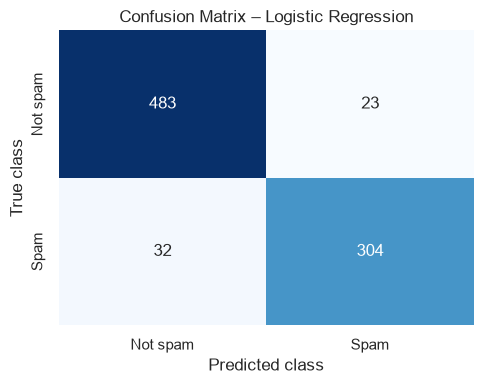

In [31]:
# Logistic Regression must be evaluated on the SCALED test data (the same format it was trained on)
lr_results = evaluate_model("Logistic Regression", log_reg, X_test_scaled)

Logistic Regression classifies **93.5%** of the test e-mails correctly. Out of 506 normal e-mails, **23** were wrongly flagged as spam (false positives), and **32** of the 336 spam e-mails slipped through (false negatives). For such a simple, linear model this is a strong result.

### 5.2 Decision Tree – test results

Accuracy  : 0.905
Precision : 0.893
Recall    : 0.866
F1-score  : 0.879


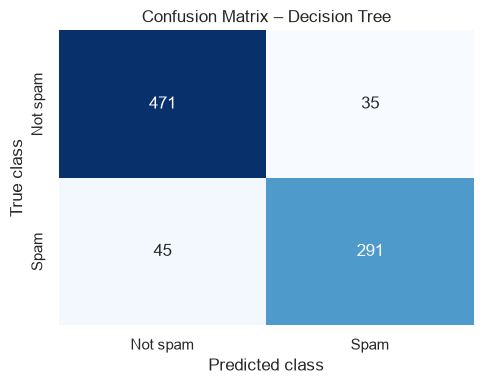

In [32]:
dt_results = evaluate_model("Decision Tree", decision_tree, X_test)

The Decision Tree is the weakest of the three, with **90.5%** accuracy. It makes the most mistakes in both directions: **35** false positives and **45** missed spam e-mails. A single tree splits the data with hard thresholds on one feature at a time, so small changes in the data can change its decisions.

### 5.3 Random Forest – test results

Accuracy  : 0.945
Precision : 0.948
Recall    : 0.914
F1-score  : 0.930


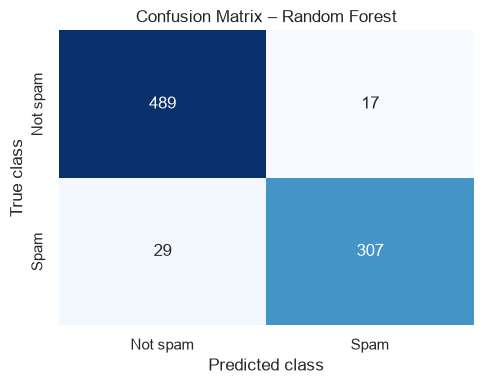

In [33]:
rf_results = evaluate_model("Random Forest", random_forest, X_test)

The Random Forest is the best model on every metric, with **94.5%** accuracy and **94.8%** precision. It has the fewest false positives (**17**), so it wrongly blocks the fewest real e-mails, and the fewest missed spam (**29**).

### 5.4 Comparison of all models

In [34]:
# Put the three result dictionaries into one table (one row per model)
comparison = pd.DataFrame([lr_results, dt_results, rf_results]).set_index("Model")

# Add the mean cross-validation F1 from Step 4 (computed on the training set only)
comparison["CV F1 (train, 5-fold)"] = [lr_cv_f1.mean(), dt_cv_f1.mean(), rf_cv_f1.mean()]

# Sort from best to worst F1-score and round for display
comparison = comparison.sort_values("F1-score", ascending=False)
comparison.round(3)

,Accuracy,Precision,Recall,F1-score,False positives,False negatives,"CV F1 (train, 5-fold)"
Model,,,,,,,
Random Forest,0.945,0.948,0.914,0.930,17,29,0.935
Logistic Regression,0.935,0.930,0.905,0.917,23,32,0.897
Decision Tree,0.905,0.893,0.866,0.879,35,45,0.888


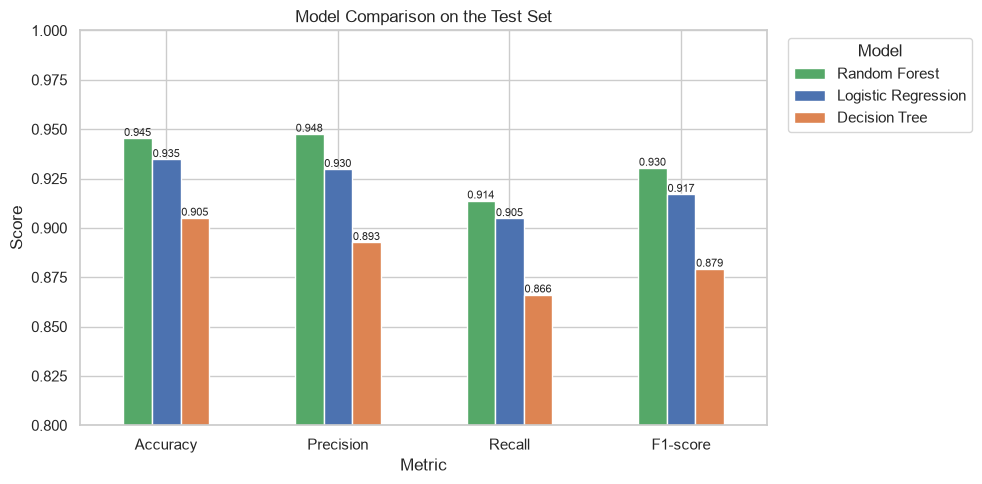

In [35]:
# Grouped bar chart of the four test metrics for each model
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]
ax = comparison[metrics].T.plot(kind="bar", figsize=(10, 5), color=["#55A868", "#4C72B0", "#DD8452"])

ax.set_title("Model Comparison on the Test Set")
ax.set_xlabel("Metric")
ax.set_ylabel("Score")
ax.set_ylim(0.8, 1.0)   # zoom in: all scores are between 0.8 and 1.0, so differences are easier to see
ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")   # put the legend outside the bars
plt.xticks(rotation=0)

# Write the value on top of every bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8)

plt.tight_layout()
plt.show()

**Random Forest > Logistic Regression > Decision Tree** on all four test metrics. The cross-validation scores on the training set show the same order, so the ranking is not just luck in how the test set was chosen. Precision is higher than recall for every model, which means the models are a bit more likely to miss spam than to block a real e-mail. For a spam filter, this is the preferred direction.

## Step 6 – Findings

### 6.1 Which features matter most?

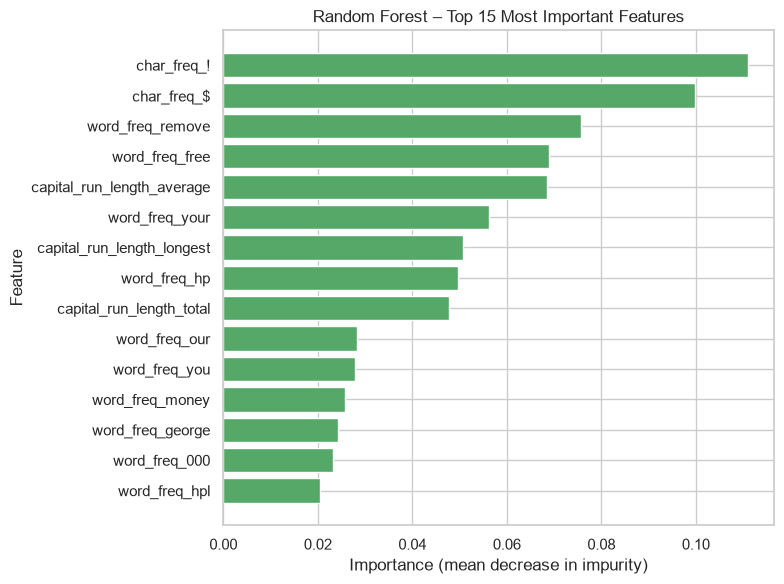

In [36]:
# Random Forest measures how much each feature helped the trees make good splits ("importance").
importances = pd.Series(random_forest.feature_importances_, index=X.columns)
top15 = importances.sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top15.index, top15.values, color="#55A868")
ax.invert_yaxis()   # most important feature at the top
ax.set_title("Random Forest – Top 15 Most Important Features")
ax.set_xlabel("Importance (mean decrease in impurity)")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

The most important features for the Random Forest are the characters `!` and `$`, the words `remove`, `free` and `your`, and the capital-letter features. This matches what we saw in Step 2. Spam e-mails use more exclamation marks, more money symbols, "remove me" links and more CAPITAL letters. `hp` also ranks high because it is a strong sign of a **non-spam** e-mail.

### 6.2 Best model and why

**Random Forest is the best model.** On the test set it reached **94.5% accuracy, 94.8% precision, 91.4% recall and an F1-score of 0.930**. It also had the fewest false positives (17 of 506 normal e-mails, about 3.4%).

Why it performs best:
- **It combines many trees.** One Decision Tree overfits and makes unstable decisions (90.5% accuracy). Averaging 300 different trees cancels out many of their individual mistakes.
- **It captures non-linear patterns and feature interactions.** For example, "many `!` *and* many capital letters" is a stronger spam signal than either one alone. Logistic Regression can only add up weighted features in a straight line, so it misses some of these combinations.
- **It handles the data's properties well.** The features are sparse (mostly zeros), skewed, and on very different scales. Tree-based models are not affected by any of this, so no scaling is needed.

Logistic Regression is a close second (F1 = 0.917). It is also faster and easier to explain, so it would be a reasonable choice if simplicity mattered more than the last 1–2% of performance.

### 6.3 Limitations

- **Old and specific data.** The e-mails were collected around 1999 from one company (HP Labs). Words like `george`, `hp`, `650` and `1999` are personal to that mailbox, so the model would not work as well for other users or for modern spam.
- **Bag-of-words features.** Each feature only counts how often a word appears. Word order, meaning and context are lost, and spammers can avoid the filter by changing spellings (e.g. "fr€e").
- **Fixed vocabulary.** Only 48 pre-selected words and 6 characters are available, and we cannot add new features because the raw e-mail text is not included.
- **Small amount of label noise.** We found 3 pairs of e-mails with identical features but opposite labels.
- **Limited tuning.** The Random Forest used default settings, and all models used the default 0.5 probability threshold. Neither was optimised for keeping false positives low.

### 6.4 Suggested improvement

**Tune the Random Forest and adjust its decision threshold to reduce false positives.** First, use `GridSearchCV` with cross-validation on the training set (as we did for the Decision Tree) to search settings such as `n_estimators`, `max_depth`, `min_samples_leaf` and `max_features`. Next, instead of the default rule "spam if probability ≥ 0.5", choose a higher threshold, for example 0.6–0.7, based on a precision–recall curve. This would reduce the number of real e-mails sent to the spam folder, which is the most harmful mistake for users. In return, slightly more spam would get through.

### 6.5 Conclusion

We built a spam classifier using the UCI Spambase dataset (4,601 e-mails, of which 4,210 remain after removing duplicates). After exploring and preparing the data with a stratified 80/20 split and scaling fitted on the training set only, we trained Logistic Regression, a Decision Tree and a Random Forest. The **Random Forest performed best (94.5% accuracy, F1 = 0.930)**, followed closely by Logistic Regression. The results show that simple word and character frequencies, such as `!`, `$`, `free` and `remove`, are strong signals for detecting spam.